In [34]:
# import things
# import things
# model
import os
import numpy as np
import cv2
from glob import glob
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras import backend as K
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.metrics import MeanIoU
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping


In [35]:
# REQUIREMENT: Do not add code from Tasks 2 or 4
# REQUIREMENT: All dataset prep (crop/pad/patch/directory structure) must be finalize before attempting this task.
patch_size = 256
patch_dir = 'output_patches_256'

In [36]:


def f1(y_true, y_pred):
    def recall_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Positives = K.sum(K.round(K.clip(y_true, 0, 1)))
        recall = TP / (Positives+K.epsilon())
        return recall
    
    def precision_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Pred_Positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
        precision = TP / (Pred_Positives+K.epsilon())
        return precision
    
    precision, recall = precision_m(y_true, y_pred), recall_m(y_true, y_pred)
    
    return 2*((precision*recall)/(precision+recall+K.epsilon()))

In [37]:
# Define U-Net

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(filters, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    return x

def simple_unet_model(input_shape=(256, 256, 3)):
    inputs = layers.Input(shape=input_shape)

    # Encoder
    c1 = conv_block(inputs, 64)
    p1 = layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, 128)
    p2 = layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, 256)
    p3 = layers.MaxPooling2D()(c3)

    c4 = conv_block(p3, 512)
    p4 = layers.MaxPooling2D()(c4)

    # Bridge
    bn = conv_block(p4, 1024)

    # Decoder
    u1 = layers.Conv2DTranspose(512, 2, strides=2, padding='same')(bn)
    u1 = layers.concatenate([u1, c4])
    c5 = conv_block(u1, 512)

    u2 = layers.Conv2DTranspose(256, 2, strides=2, padding='same')(c5)
    u2 = layers.concatenate([u2, c3])
    c6 = conv_block(u2, 256)

    u3 = layers.Conv2DTranspose(128, 2, strides=2, padding='same')(c6)
    u3 = layers.concatenate([u3, c2])
    c7 = conv_block(u3, 128)

    u4 = layers.Conv2DTranspose(64, 2, strides=2, padding='same')(c7)
    u4 = layers.concatenate([u4, c1])
    c8 = conv_block(u4, 64)

    outputs = layers.Conv2D(1, 1, activation='sigmoid')(c8)

    return models.Model(inputs, outputs)


In [38]:
# Build U-Net
# REQUIREMENT: Model summary must be visible
model = simple_unet_model()
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_57 (Conv2D)  │ (None, 256, 256,  │      1,792 │ input_layer_3[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        256 │ conv2d_57[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_54       │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_58 (Conv2D)  │ (None, 256, 256,  │     36,928 │ activation_54[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        256 │ conv2d_58[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_55       │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_12    │ (None, 128, 128,  │          0 │ activation_55[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_59 (Conv2D)  │ (None, 128, 128,  │     73,856 │ max_pooling2d_12… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        512 │ conv2d_59[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_56       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_60 (Conv2D)  │ (None, 128, 128,  │    147,584 │ activation_56[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        512 │ conv2d_60[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_57       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_13    │ (None, 64, 64,    │          0 │ activation_57[0]… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_61 (Conv2D)  │ (None, 64, 64,    │    295,168 │ max_pooling2d_13… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │      1,024 │ conv2d_61[0][0] 

 Total params: 31,055,297 (118.47 MB)

 Trainable params: 31,043,521 (118.42 MB)

 Non-trainable params: 11,776 (46.00 KB)

In [39]:
from tensorflow.keras.utils import Sequence
import cv2
import numpy as np
import random

class SegmentationGenerator(Sequence):
    def __init__(self, image_paths, mask_paths, batch_size=16, augment=False, shuffle=True):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.batch_size = batch_size
        self.augment = augment
        self.shuffle = shuffle
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.image_paths) / self.batch_size))

    def __getitem__(self, index):
        batch_img_paths = self.image_paths[index * self.batch_size:(index + 1) * self.batch_size]
        batch_msk_paths = self.mask_paths[index * self.batch_size:(index + 1) * self.batch_size]

        images, masks = [], []

        for img_path, msk_path in zip(batch_img_paths, batch_msk_paths):
            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = img.astype(np.float32) / 255.0

            msk = cv2.imread(msk_path, cv2.IMREAD_GRAYSCALE)
            msk = (msk > 0).astype(np.float32)  # Binary mask
            msk = msk[..., np.newaxis]  # Expand channel

            # Augmentation
            if self.augment:
                if random.random() > 0.5:
                    img = np.fliplr(img)
                    msk = np.fliplr(msk)
                if random.random() > 0.5:
                    img = np.flipud(img)
                    msk = np.flipud(msk)

            images.append(img)
            masks.append(msk)

        return np.array(images), np.array(masks)

    def on_epoch_end(self):
        if self.shuffle:
            temp = list(zip(self.image_paths, self.mask_paths))
            random.shuffle(temp)
            self.image_paths, self.mask_paths = zip(*temp)


In [40]:
import glob
import os

train_img_dir = 'output_patches_256/train/images'
train_msk_dir = 'output_patches_256/train/masks'

# Match images and masks
val_img_dir = 'output_patches_256/val/images'
val_msk_dir = 'output_patches_256/val/masks'

# Match images and masks
train_imgs = sorted(glob.glob(os.path.join(train_img_dir, '*.png')))
train_msks = sorted(glob.glob(os.path.join(train_msk_dir, '*.tif')))

val_imgs = sorted(glob.glob(os.path.join(val_img_dir, '*.png')))
val_msks = sorted(glob.glob(os.path.join(val_msk_dir, '*.tif')))

In [41]:
# Setup a generator for training
train_generator = SegmentationGenerator(train_imgs, train_msks, batch_size=16, augment=True)
print(f"Found {len(train_imgs)} training images.")
print(f"Found {len(train_msks)} training masks.")

Found 2647 training images.
Found 2647 training masks.


In [42]:
# Setup a generator for validation
val_generator = SegmentationGenerator(val_imgs, val_msks, batch_size=16, augment=True)
print(f"Found {len(val_imgs)} val images.")
print(f"Found {len(val_msks)} val masks.")


Found 130 val images.
Found 130 val masks.


In [43]:
# EarlyStopping()
from keras.callbacks import EarlyStopping,ModelCheckpoint
cb = EarlyStopping(
    monitor='val_f1',      # metric to monitor
    mode='max',            # maximize F1
    patience=10,           # stop if no improvement after 10 epochs
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "jaberi_244437_unet_model_256px.h5",  # Replace with your ID
    monitor='val_f1',
    mode='max',
    save_best_only=True,
    verbose=1
)


model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[f1]
)

In [44]:
# This is where the magic happens
# REQUIREMENT: The epoch logs must be visible showing validation loss and validation f1.
history = model.fit(
    train_generator,
    validation_data=val_generator,
    batch_size=16,
    epochs=50,
    callbacks=[cb, checkpoint]
)

Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
2025-12-18 20:00:35.357598: I external/local_xla/xla/service/service.cc:163] XLA service 0x7f7aa8002440 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2025-12-18 20:00:35.357633: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA RTX 6000 Ada Generation, Compute Capability 8.9
2025-12-18 20:00:35.571395: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2025-12-18 20:00:37.007915: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473]

  1/166 ━━━━━━━━━━━━━━━━━━━━ 2:25:27 53s/step - f1: 0.0559 - loss: 0.7039

I0000 00:00:1766088079.955480  230985 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


105/166 ━━━━━━━━━━━━━━━━━━━━ 8s 137ms/step - f1: 0.3052 - loss: 0.2228 

...

166/166 ━━━━━━━━━━━━━━━━━━━━ 28s 170ms/step - f1: 0.8160 - loss: 0.0202 - val_f1: 0.8615 - val_loss: 0.0112
Epoch 28/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - f1: 0.8175 - loss: 0.0195 
Epoch 28: val_f1 did not improve from 0.86153
166/166 ━━━━━━━━━━━━━━━━━━━━ 27s 159ms/step - f1: 0.8166 - loss: 0.0201 - val_f1: 0.8248 - val_loss: 0.0144
Epoch 29/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - f1: 0.8203 - loss: 0.0198 
Epoch 29: val_f1 did not improve from 0.86153
166/166 ━━━━━━━━━━━━━━━━━━━━ 25s 152ms/step - f1: 0.8210 - loss: 0.0198 - val_f1: 0.8552 - val_loss: 0.0112
Epoch 30/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - f1: 0.8212 - loss: 0.0196 
Epoch 30: val_f1 did not improve from 0.86153
166/166 ━━━━━━━━━━━━━━━━━━━━ 26s 153ms/step - f1: 0.8201 - loss: 0.0198 - val_f1: 0.8412 - val_loss: 0.0124
Epoch 31/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - f1: 0.8247 - loss: 0.0189 
Epoch 31: val_f1 did not improve from 0.86153
166/166 ━━━━━━━━━━━━━━━━━━━━ 27s 160ms/step - f1

166/166 ━━━━━━━━━━━━━━━━━━━━ 28s 168ms/step - f1: 0.8209 - loss: 0.0197 - val_f1: 0.8622 - val_loss: 0.0122
Epoch 33/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - f1: 0.8259 - loss: 0.0187 
Epoch 33: val_f1 did not improve from 0.86223
166/166 ━━━━━━━━━━━━━━━━━━━━ 27s 162ms/step - f1: 0.8227 - loss: 0.0193 - val_f1: 0.8456 - val_loss: 0.0111
Epoch 34/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - f1: 0.8254 - loss: 0.0187 
Epoch 34: val_f1 did not improve from 0.86223
166/166 ━━━━━━━━━━━━━━━━━━━━ 27s 158ms/step - f1: 0.8228 - loss: 0.0194 - val_f1: 0.8543 - val_loss: 0.0127
Epoch 35/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - f1: 0.8214 - loss: 0.0196 
Epoch 35: val_f1 did not improve from 0.86223
166/166 ━━━━━━━━━━━━━━━━━━━━ 25s 151ms/step - f1: 0.8240 - loss: 0.0190 - val_f1: 0.8578 - val_loss: 0.0115
Epoch 36/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - f1: 0.8233 - loss: 0.0188 
Epoch 36: val_f1 did not improve from 0.86223
166/166 ━━━━━━━━━━━━━━━━━━━━ 25s 152ms/step - f1

166/166 ━━━━━━━━━━━━━━━━━━━━ 27s 161ms/step - f1: 0.8272 - loss: 0.0188 - val_f1: 0.8656 - val_loss: 0.0106
Epoch 39/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - f1: 0.8276 - loss: 0.0184 
Epoch 39: val_f1 did not improve from 0.86555
166/166 ━━━━━━━━━━━━━━━━━━━━ 25s 151ms/step - f1: 0.8269 - loss: 0.0188 - val_f1: 0.8396 - val_loss: 0.0120
Epoch 40/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - f1: 0.8266 - loss: 0.0186 
Epoch 40: val_f1 improved from 0.86555 to 0.87021, saving model to jaberi_244437_unet_model_256px.h5


166/166 ━━━━━━━━━━━━━━━━━━━━ 28s 167ms/step - f1: 0.8267 - loss: 0.0188 - val_f1: 0.8702 - val_loss: 0.0107
Epoch 41/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - f1: 0.8280 - loss: 0.0179 
Epoch 41: val_f1 did not improve from 0.87021
166/166 ━━━━━━━━━━━━━━━━━━━━ 27s 156ms/step - f1: 0.8261 - loss: 0.0189 - val_f1: 0.8273 - val_loss: 0.0146
Epoch 42/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - f1: 0.8287 - loss: 0.0197 
Epoch 42: val_f1 did not improve from 0.87021
166/166 ━━━━━━━━━━━━━━━━━━━━ 26s 157ms/step - f1: 0.8299 - loss: 0.0186 - val_f1: 0.8624 - val_loss: 0.0112
Epoch 43/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - f1: 0.8311 - loss: 0.0179 
Epoch 43: val_f1 improved from 0.87021 to 0.87066, saving model to jaberi_244437_unet_model_256px.h5


166/166 ━━━━━━━━━━━━━━━━━━━━ 28s 163ms/step - f1: 0.8340 - loss: 0.0181 - val_f1: 0.8707 - val_loss: 0.0104
Epoch 44/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - f1: 0.8327 - loss: 0.0178 
Epoch 44: val_f1 did not improve from 0.87066
166/166 ━━━━━━━━━━━━━━━━━━━━ 27s 160ms/step - f1: 0.8340 - loss: 0.0180 - val_f1: 0.8702 - val_loss: 0.0102
Epoch 45/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - f1: 0.8318 - loss: 0.0182 
Epoch 45: val_f1 did not improve from 0.87066
166/166 ━━━━━━━━━━━━━━━━━━━━ 27s 160ms/step - f1: 0.8311 - loss: 0.0183 - val_f1: 0.8516 - val_loss: 0.0110
Epoch 46/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - f1: 0.8343 - loss: 0.0177 
Epoch 46: val_f1 did not improve from 0.87066
166/166 ━━━━━━━━━━━━━━━━━━━━ 25s 151ms/step - f1: 0.8341 - loss: 0.0180 - val_f1: 0.8571 - val_loss: 0.0106
Epoch 47/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - f1: 0.8245 - loss: 0.0187 
Epoch 47: val_f1 did not improve from 0.87066
166/166 ━━━━━━━━━━━━━━━━━━━━ 26s 154ms/step - f1

In [45]:
# REQUIREMENT: Save your model, it is a deliverable
# REQUIREMENT: naming convention 'studentname_studentnumber_unet_model_patchsizepx.h5'
patch_size = 256
example_file_name = f'MoaliJaberi_244437_unet_model_{patch_size}px.h5'
print(example_file_name)
model.save(example_file_name)

MoaliJaberi_244437_unet_model_256px.h5


In [46]:
# REQUIREMENT: Run and display the output of this cell.
# REQUIREMENT: Do not change the code.
best_val_loss = min(history.history['val_loss'])
best_val_f1 = max(history.history['val_f1'])
print(f"Best validation loss: {best_val_loss}")
print(f"Best validation f1: {best_val_f1}")

Best validation loss: 0.010112425312399864
Best validation f1: 0.8706640005111694


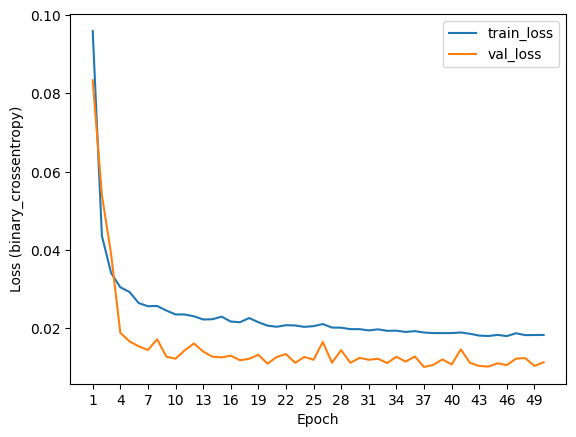

In [47]:
# REQUIREMENT: Run and display the output of this cell.
# REQUIREMENT: Do not change the code.
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = np.arange(1, len(loss) + 1)

plt.plot(epochs, loss, label='train_loss')
plt.plot(epochs, val_loss, label='val_loss')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss (binary_crossentropy)')
_ = plt.xticks(np.arange(1, len(loss) + 1, 3))

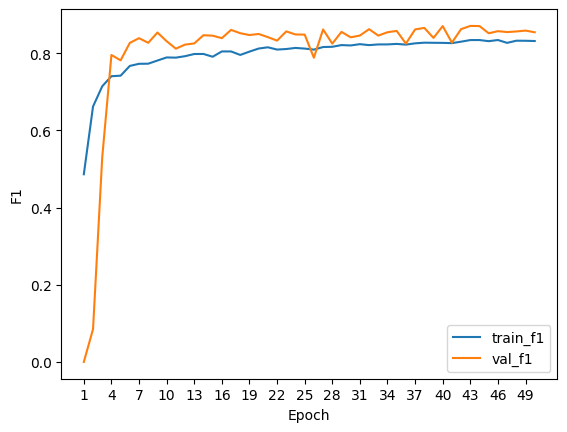

In [48]:
# REQUIREMENT: Run and display the output of this cell.
# REQUIREMENT: Do not change the code.
train_f1 = history.history['f1']
val_f1 = history.history['val_f1']

epochs = np.arange(1, len(train_f1) + 1)

plt.plot(epochs, train_f1, label='train_f1')
plt.plot(epochs, val_f1, label='val_f1')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('F1')
_ = plt.xticks(np.arange(1, len(loss) + 1, 3))